## Imports:

In [205]:
%load_ext autoreload
%autoreload 2

import os
import sys
import random
from dotenv.main import load_dotenv

load_dotenv()
REPO_PATH = os.getenv('REPO_PATH')

sys.path.append(REPO_PATH)

from knowledge_maze.tools.utils import load_json, display_usage_log
from knowledge_maze.create_dataset.create_questions.wikipedia_mining import WikiMiner
from knowledge_maze.create_dataset.create_questions.table_processing import AsyncWikiExtractor, TablePostProcessor
from knowledge_maze.create_dataset.create_questions.grouping_entities import TableGroupConstructor, GroupValidator
from knowledge_maze.create_dataset.create_questions.question_generation import TableSanitizer, StrategySelector, QuestionGenerator, QuestionFilter
from knowledge_maze.create_dataset.create_questions.question_validator import ManualTagger
from knowledge_maze.create_dataset.create_questions.visualization import plot_strategy_sunburst, plot_evidence_distribution, plot_subject_distribution, visualize_samples

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [357]:
# Display Open Router usage log: 
display_usage_log()

Open Router all time usage cost: 6.438$
Daily usage:
 - 2026-03-22: 4.457$
 - 2026-03-23: 1.981$


# Data Creation:

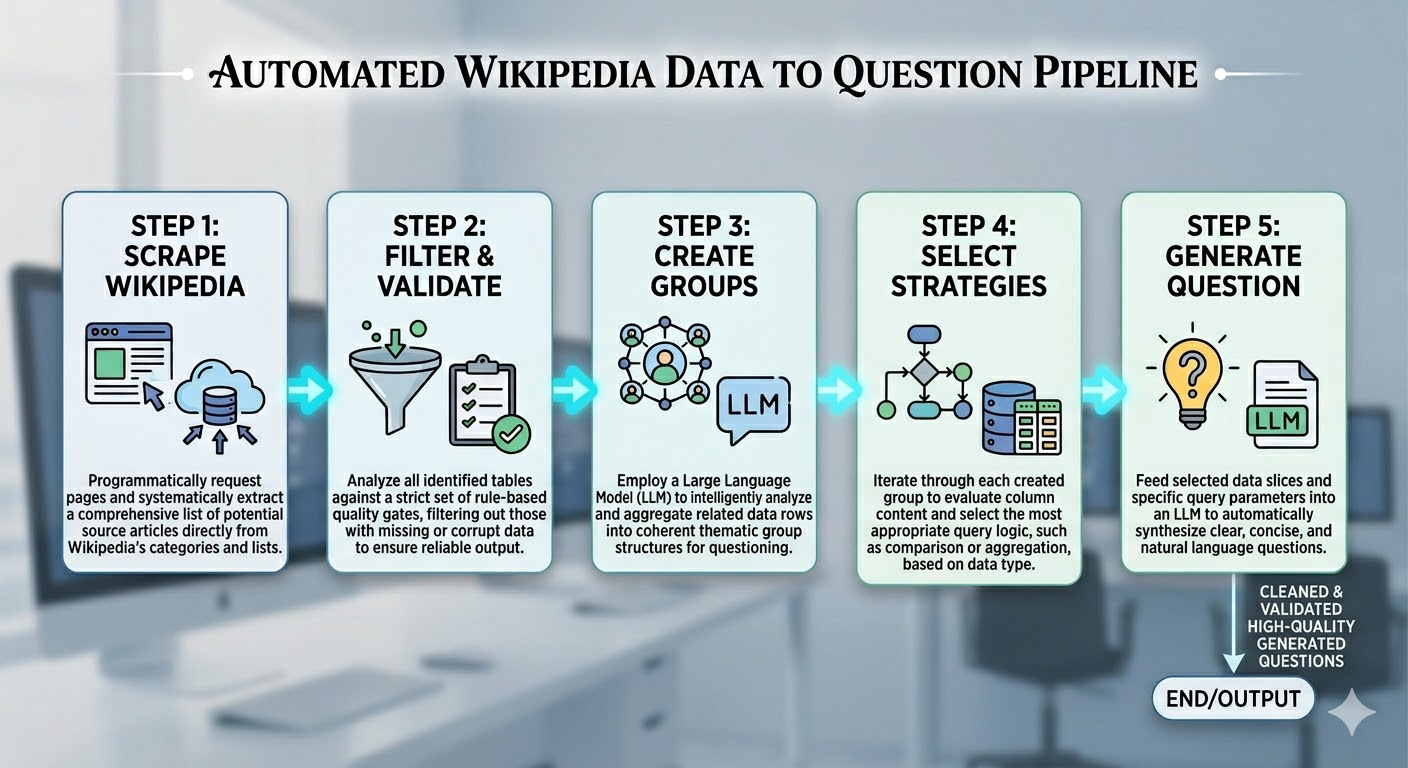

## 1. Harvest Wikipedia pages with tables:

1. **The Discovery Phase (The Wide Net)**
   - Input: 22 Subject Groups (e.g., Infrastructure, Sports).
   - Action: We hit the Wikipedia API with two distinct patterns:
     - Prefix Mining: Grabbing every page starting with "Entity in/of..."
     - Search Mining: Finding every page with "List of [Entity]" in the title.
     - Goal: Maximum recall. We want to find everything that might be a list.
2. **The Validation Phase (The Filter)**
   - Action: We open every page found in Phase 1 (asynchronously for speed).
   - Logic: We look for the "DNA" of a table: the {| or wikitable tags.
   - Outcome: We discard the "stub" articles or prose-only pages that don't actually contain structured data.
3. **The Clustering Phase (The De-duplicator)**
   - Problem: Wikipedia often has "List of 2023 Films" and "List of films of 2023." These are duplicates.
   - Action: Using TF-IDF to cluster similar page titles.
   - If two titles are >80% similar, we draw a line (edge) between them.
   - Pick a representative from each cluster to continue.

In [12]:
miner = WikiMiner()
await miner.extract()

Mining Pages:   0%|          | 0/320 [00:00<?, ?entity/s]

Filtering Pages with Tables:   0%|          | 0/89666 [00:00<?, ?page/s]

Computing Similarities for 43937 Titles:   0%|          | 0/43937 [00:00<?, ?titles/s]

Picking Representatives from 39391 Clusters:   0%|          | 0/39391 [00:00<?, ?cluster/s]

## 2. Parse and filter valid Wikipedia tables:

1. **Geometric Fix** - Rebuilds the "hidden grid" of the table. It maps merged cells (rowspans) to their correct spots so the data doesn't shift.
2. **Context Grab** - Captures the Section Path (e.g., Earthquakes > 1954) and the Intro Sentence above the table to explain what the data means.
3. **Trash Filter** - Deletes "Legend" tables, empty tables, and tiny snippets. If it's less than 4 rows or 50% empty, it’s gone.
4. **Variety Control** - "Detects ""Clones"" (like 12 identical monthly tables). It keeps a maximum of 4 different tables per page to ensure the dataset isn't boring.

In [151]:
extractor = AsyncWikiExtractor(output_file=os.path.join(REPO_PATH, "data_files/candidate_tables.jsonl"))
validated_tables_file_name = await extractor.run_with_progress(load_json(os.path.join(REPO_PATH, "data_files/valid_titles.json")))

processor = TablePostProcessor(os.path.join(REPO_PATH, "data_files/candidate_tables.jsonl"))
cleaned_data = processor.process()

Filtering & Cleaning:   0%|          | 0/64646 [00:00<?, ?it/s]

Legend / Key Filter,553
Header Parsing Failures,"3,883"
Cell Content Too Long,"1,936"
Malformed Row Structures,"1,603"
Alphabetical Lists Removed,639
Tables with no Headers,585
Long Tables Removed,"31,673"
Intra-Page Duplicates Removed,"8,883"


In [5]:
processor.display_sample()

,Order,Grand Finalist,Age,Winner of Episode...,Appeared as,Performing,Total score,Place
0,1,Lewis Devine,14,1 (21 July 2001),Donny Osmond,""" The Twelfth of Never """,35411,5th
1,2,Louise Emmanuel,16,3 (7 September 2002),Irene Cara,"""Fame""",25096,6th
2,3,Charlotte Gethin,14,2 (31 August 2002),Eva Cassidy,"""Over the Rainbow""",282422,1st
3,4,Porsha Mavour,10,5 (21 September 2002),Millie Small,"""My Boy Lollipop""",79674,3rd
4,5,Amanda Tinkler,16,4 (14 September 2002),Nelly Furtado,"""I'm Like A Bird""",55638,4th
5,6,Russell Parsons,16,6 (28 September 2002),Robbie Williams,"""Let Me Entertain You""",142887,2nd


## 3. Create Potential Entity Groups:

A table is considered a valid **entity group** if it satisfies the following conditions:

- **Entity Column:** The table must contain a column where each cell is a unique instance of the same entity type (e.g., person, film, city, team).
- **Subject Over Data:** The group name must describe **what the rows are**, not attributes or statistics about them.
- **Entity–Name Alignment:** The group name must accurately match the type of entities in the entity column.
- **No Repeated Labels:** The entity column cannot contain generic labels or repeated categories (e.g., "Height", "Weight").
- **No Summary Tables:** Tables that summarize metrics (e.g., "Total Population", "Revenue") rather than listing entities are invalid.
- **Clear Grouping Rule:** The group must explain why these entities appear together (e.g., *Top 10 films by revenue*, *Citrus fruits*).
- **Closed and Coherent Set:** The rows cannot be a random subset of a larger category unless a clear filter exists (e.g., ranking, time constraint).
- **Member Consistency:** All entities must logically belong to the group definition.
- **Specific Category:** The group must use precise and objective definitions; vague terms like "famous" or "important" are not allowed.
- **Natural Category:** The grouping must reflect a meaningful category that humans would reasonably recognize.
- **Context Usage:** Headers, captions, and nearby text may be used to refine the group definition when informative.
- **Conservative Validation:** If the grouping logic is unclear or ambiguous, the table should be rejected.


In [212]:
group_constructor = TableGroupConstructor(random.sample(cleaned_data, 1000))
await group_constructor.get_groups()

Creating 1000 Entity Groups:   0%|          | 0/1000 [00:00<?, ?it/s]

LLM Rejected,93
Duplicate Entities Found,137
Empty Entity Cells,5
Entity Column has Numeric/Date Values,59
Kill-List Keywords in Group Name,25
Top-X Mismatch,1
Entity Column in Kill-List,1


In [213]:
group_constructor.display_debug_samples()

### Validate a small subset using Gemini 3.1 pro:

### RULES FOR VALIDITY

1. **FATEFULNESS:** Members must logically match the Group Name. Reject if the description is misleading, overly broad, or contains unrelated concepts.
2. **CLOSED_SET:** The group must be coherent and complete. Reject random subsets (e.g., "6 random cities in France"). 
   *Exception:* Specific filters (e.g., "Top 10", "Oldest 5", "Members in 2024") are valid.
3. **SPECIFICALITY:** The group must have a narrow, clear concept. Reject vague names like "Famous movies" or "Important countries."
4. **NATURALNESS:** The category must be one that humans would reasonably group together. Reject arbitrary rules (e.g., "Cities starting with Q that have 3 vowels").
5. **CORRECT_ENTITY:** The Entity Column must contain the primary entities, not metadata (Rank, Year, ID) or attributes.

In [354]:
group_val = GroupValidator(random.sample(group_constructor.valid_tables, 200))
await group_val.validate()

Evaluating Group Samples:   0%|          | 0/200 [00:00<?, ?it/s]

"● CLOSED_SET 2 Children's animated television series from the United Kingdom released in the 2010s The group contains only 7 entities, which is an incomplete subset of all UK children's animated television series released in the 2010s (missing notable shows like Octonauts, Bing, and Danger Mouse)."
"● CORRECT_ENTITY 1 Club captains of Kerala Blasters FC The entity column contains multiple names concatenated together without delimiters (e.g., 'Iain Hume David James Cédric Hengbart Penn Orji'), indicating a parsing error rather than clean individual entities."
"● FATEFULNESS 2 Eastern Catholic eparchs of American eparchies immediately subject to the Holy See The entity list includes 'Sede Vacante', which is a Latin term for a vacant seat, not an actual person or eparch, making the members logically inconsistent with the group name."
"● NATURALNESS 3 Top 6 Caribbean islands with an area between 10 and 29 km2 The group is defined by an arbitrary area range (between 10 and 29 km2) and an arbitrary limit (Top 6), which does not form a natural or meaningful category."


## 4. Select Preferred Question Strategies for each Entity Group:

**1. Table Sanitizer - Clean the noise and infer data types:**
   - Ref-Stripping: Removes Wikipedia footnotes (e.g., [1], [a]) and fuzzy prefixes (~, >, approx).
   - Unit Validation: Only treats strings as numbers if they match VALID_METRICS (kg, m, %, $) to avoid "5 dogs" being indexed as a float.
   - Auto-Scaling: Converts "1.2 billion" into 1,200,000,000 automatically.Trash Filtering: Prunes metadata columns (Rank, Notes, Index) and low-density columns (>50% empty).

**2. Strategy Selection - Determine the most "natural" questions for each table:**
   - Outlier Detection: Boosts EXTREME_NUMERICAL if a value is $> 2\times$ the column mean.
   - Clump Analysis: Triggers FILTER_COUNT or FREQUENCY_MODE if values repeat (e.g., multiple items from the same "Category").
   - Temporal Heuristics: Identifies years (1000–2100) to pivot toward "Earliest/Latest" logic.
   - Entity Guardrail: Discards tables where the subject column is purely numeric or contains nulls.

**3. Quality Scoring & Slicing - Final validation and data reduction:**
   - The 0.45 Threshold: Strategies must score $> 0.45$ to be considered "interesting" enough for the dataset.
   - Data Slicing: Generates "Strategy Views"—minimal sub-tables containing only the columns required for the chosen question type.
   - Triviality Check: Blocks "Count" questions if the count is already leaked in the table title (e.g., "Top 10...").

In [214]:
selector = StrategySelector(group_constructor.valid_tables)
selector.get_strategies()

Sanitizing tables:   0%|          | 0/679 [00:00<?, ?it/s]

Slicing strategy views:   0%|          | 0/679 [00:00<?, ?it/s]

Strategy Name,Selection Count
COUNT_TOTAL,362
EXTREME_TEMPORAL,304
FILTER_COUNT_TEMPORAL,211
UNIQUE_DIVERSITY,198
FREQUENCY_MODE,157
CATEGORICAL_FILTER_LOOKUP,149
COMPARATIVE_DIFFERENCE,130
EXTREME_NUMERICAL,124
TOP_K_RANKING,117
FILTER_COUNT_NUMERICAL,96


In [215]:
selector.debug_strategy_samples("CATEGORICAL_FILTER_LOOKUP")

Award,Result
Pop Singles Awards: Top Female Vocalist,Won
Pop Singles Awards: Top New Female Vocalist,Won
Pop Album Awards: Top Female Vocalist,Won
Pop Album Awards: Top New Female Vocalist,Won
Black Contemporary Singles: Top Pop Crossover Vocalist,3rd place
"12"" Singles: Top Female Vocalist",3rd place
"12"" Singles: Top New Female Vocalist",Won
Music Video & Videocassette Awards: Top Female Vocalist,2nd place
Music Video & Videocassette Awards: Top New Female Vocalist,Won
Common name,IUCN status


## 5. Create Complex Reasoning Questions w.r.t. Entity Groups & Selected Strategies:

**1. Question Generation - Transform raw table data into natural, human-sounding questions:**
   - The "Radio Test": Questions must be self-contained. If a listener heard it on the radio, they should understand exactly what is being discussed without seeing the table.
   - Anti-AI Phrases: Strictly prohibits "According to the table" or "Based on the data." It uses a Prohibited List to force natural journalistic flow.
   - Strategy Leveling: If a table has 4 possible strategies, the generator prioritizes the one that has been "starved" (tried the least globally) to ensure a diverse dataset.
   - Subset Identification: Instead of saying "these rows," the model must identify the shared trait (e.g., "The six MLB players who...") to define the scope.

**2. Quality & Deduplication - Final audit to ensure the dataset is unique and structurally perfect:**
   - Schema Enforcement: Rejects any question where the table view accidentally contains extra columns or missing data.
   - Fuzzy Deduplication: Uses rapidfuzz to find questions that are $>85\%$ similar. If two questions are nearly identical, it keeps the one with the rarest strategy to preserve variety.
   - Strict Null Check: Any "empty" or "null" response from the LLM is immediately caught and logged as a failure.The Rarity Tie-Breaker: When two tables produce the same question (e.g., "Who won the game?"), the system checks which strategy is less common in the overall pool and saves that one.

In [236]:
generator = QuestionGenerator(selector.updated_data, strategy_definitions=load_json(os.path.join(REPO_PATH, "knowledge_maze/create_dataset/create_questions/question_strategies.json")))
await generator.generate_questions()

Round 1 - Processing 645 tables to questions:   0%|          | 0/645 [00:00<?, ?it/s]

Round 2 - Processing 15 tables to questions:   0%|          | 0/15 [00:00<?, ?it/s]

Round 3 - Processing 7 tables to questions:   0%|          | 0/7 [00:00<?, ?it/s]

Round 4 - Processing 4 tables to questions:   0%|          | 0/4 [00:00<?, ?it/s]

Strategy Name,Success,Tried,Rate
COUNT_TOTAL,153,153,100%
FILTER_COUNT_TEMPORAL,89,91,98%
EXTREME_TEMPORAL,80,85,94%
UNIQUE_DIVERSITY,50,51,98%
CATEGORICAL_FILTER_LOOKUP,49,49,100%
FREQUENCY_MODE,47,52,90%
EXTREME_NUMERICAL,38,42,90%
AGGREGATION,36,38,95%
COMPARATIVE_DIFFERENCE,34,38,89%
FILTER_COUNT_NUMERICAL,34,35,97%


In [237]:
val = QuestionFilter(generator.valid_results)
val.run_pipeline()

Starting post-processing with 643 samples...


Rule,Definition,Count
FORBIDDEN_KEYWORD,A forbidden keyword was found in the question text.,35
DUPLICATE_DATA,Question is too similar to another question in the dataset.,19
EXTRA_COLUMNS,Table contains more than one attribute column (schema violation).,2
MISSING_COLUMNS,Table lacks an attribute column for this strategy.,1
MISSING_QUESTION,Question field was empty or null.,0
MISSING_TABLE,No table data was found for this sample.,0
EMPTY_DATA,Attribute column exists but has no data rows.,0


## 6. Data Statistics:

In [238]:
question_data = load_json(os.path.join(REPO_PATH, "data_files/question_dataset.json"))

In [342]:
tagger = ManualTagger(question_data, load_json(os.path.join(REPO_PATH, "knowledge_maze/create_dataset/create_questions/question_strategies.json")))
tagger.display()

📦 Progress Loaded: 210 samples already tagged in 'tagger_progress.json'.


Output()

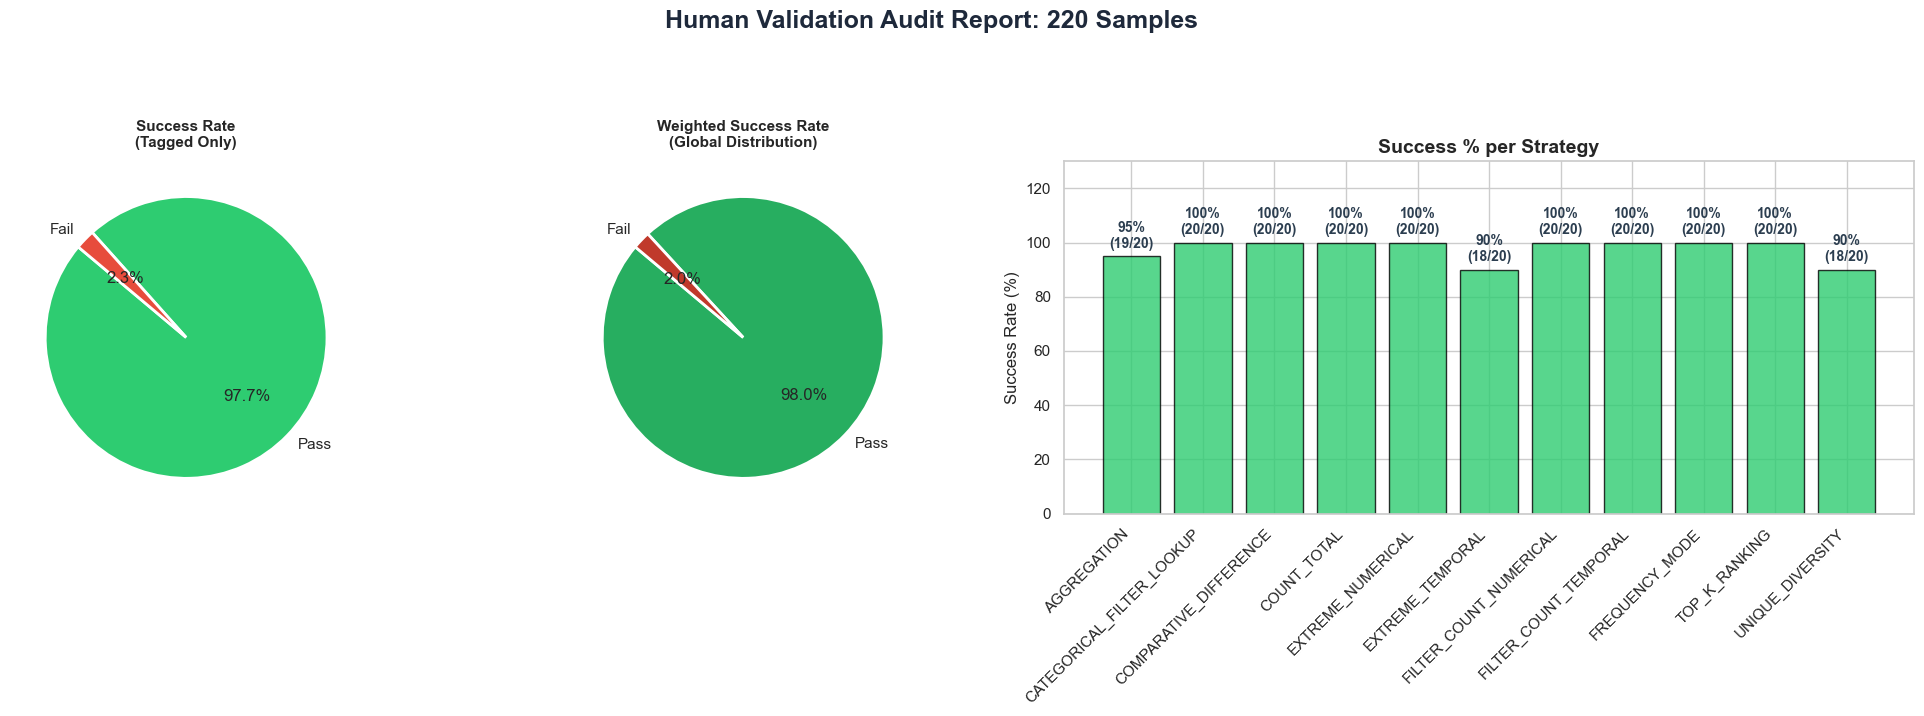

In [343]:
tagger.plot_results()

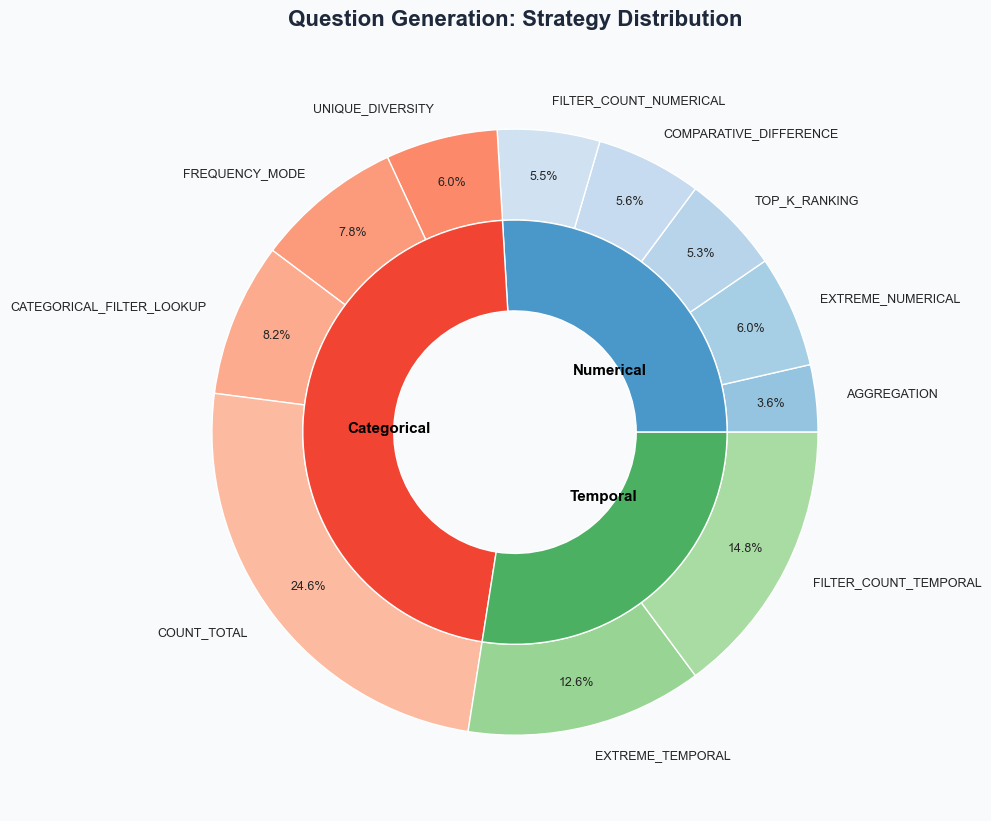

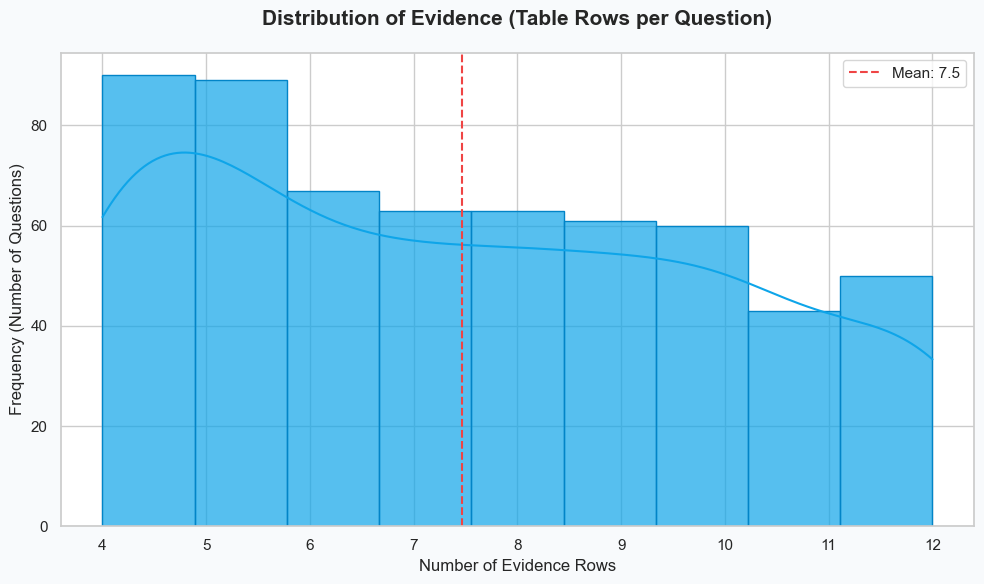

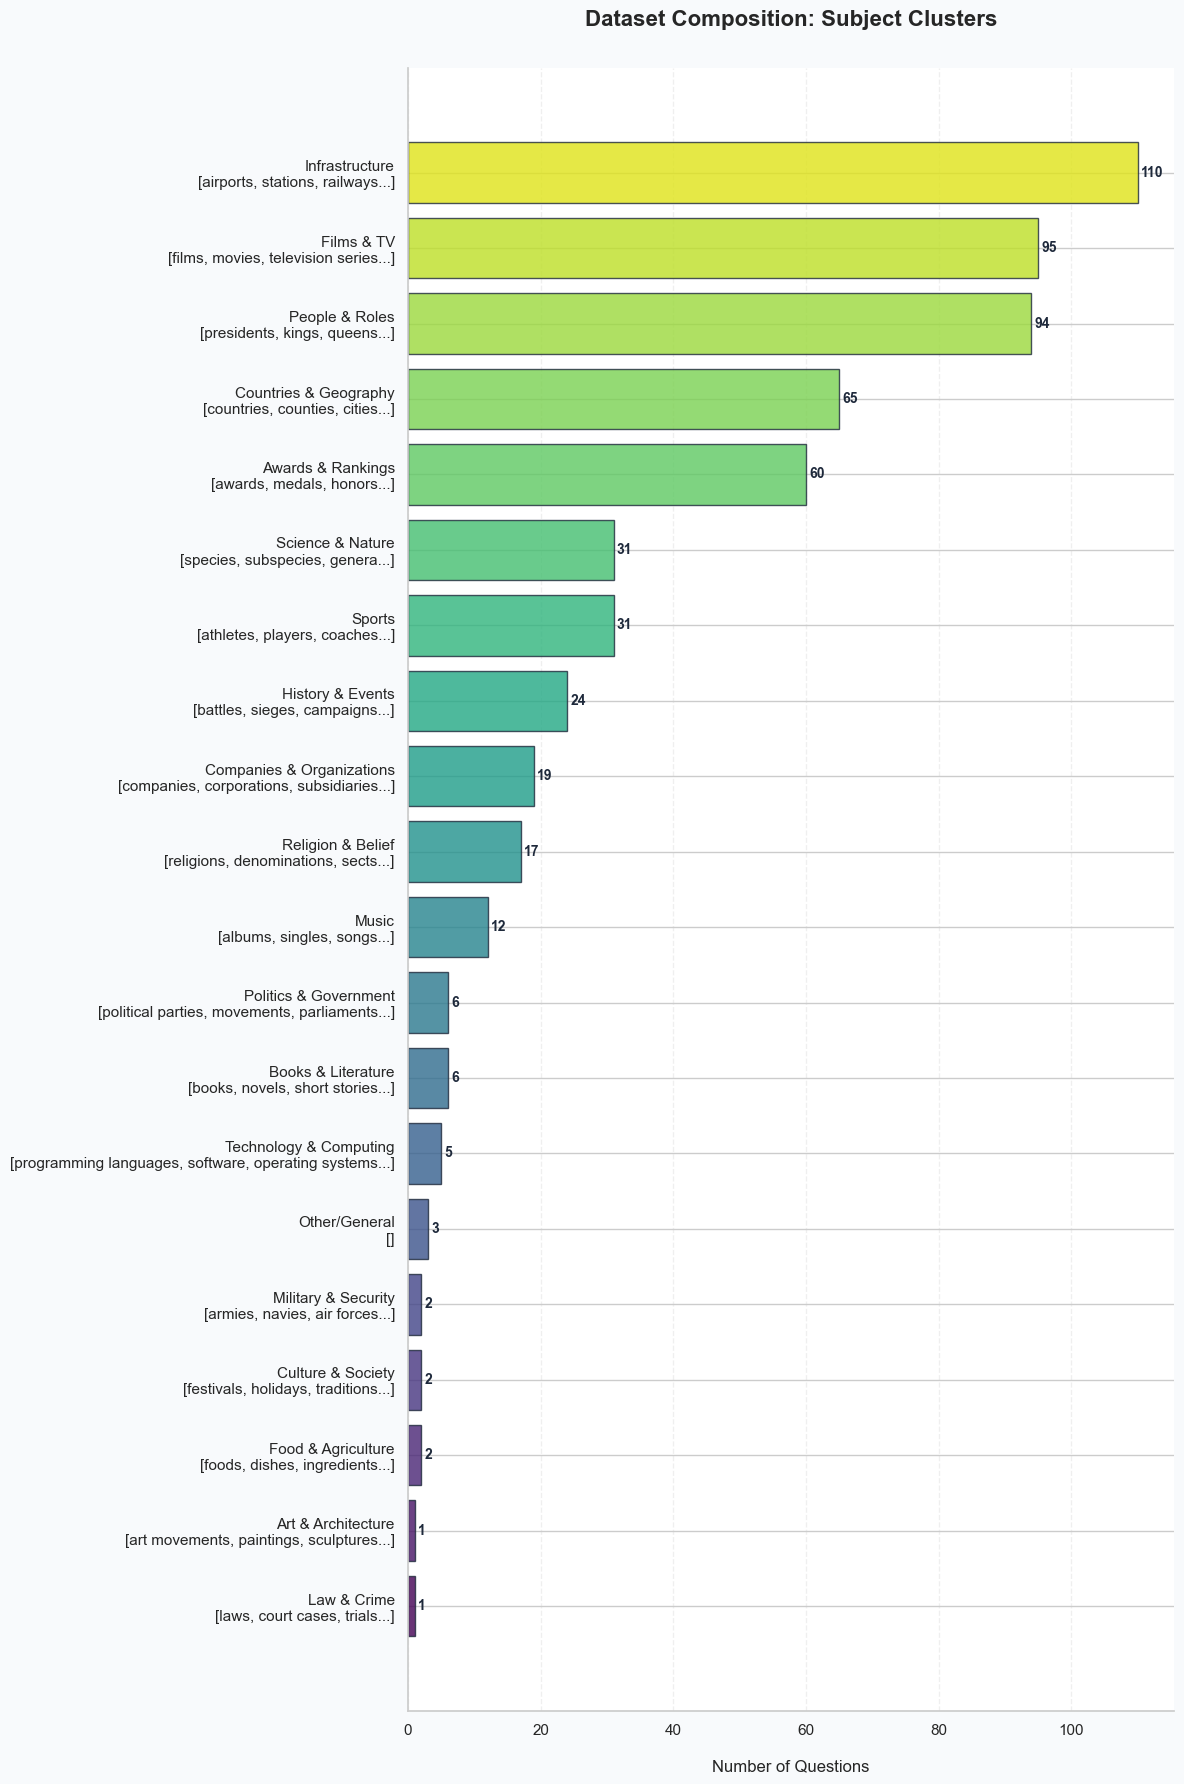

In [313]:
plot_strategy_sunburst(question_data)
plot_evidence_distribution(question_data)
plot_subject_distribution(question_data)

### Show Some Data Samples:

In [314]:
visualize_samples(question_data)

COUNT_TOTAL Stations on the Line S1 of the Beijing Subway
How many total stations are currently operational on Line S1 of the Beijing Subway?
Station
Shichang
Xiaoyuan
Liyuanzhuang
Shang'an
Qiaohuying
Sidaoqiao
Jin'anqiao
Pingguoyuan
